# Données

**train.csv**
- Id - un identifiant qui représente un duplicata (Magasin, Date) au sein de l'ensemble de test
- DayOfWeek - Jour de le semaine (0 à 6)
- Store - un identifiant unique pour chaque magasin
- Sales - le chiffre d'affaires d'une journée donnée (c'est ce que vous prévoyez)
- Promo - indique si un magasin propose une promotion ce jour-là
- Customers - le nombre de clients un jour donné
- Open – indique si le magasin était ouvert : 0 = fermé, 1 = ouvert
- StateHoliday - indique un jour férié d'État. En règle générale, tous les magasins, à quelques exceptions près, sont fermés les jours fériés d'État. Veuillez noter que toutes les écoles sont fermées les jours fériés et les week-ends. a = jour férié, b = vacances de Pâques, c = Noël, 0 = Aucun
- SchoolHoliday - indique si le (Magasin, Date) a été affecté par la fermeture des écoles publiques

**store.csv**
- Id - identifiant unique
- StoreType  - différencie 4 modèles de magasin différents : a, b, c, d
- Assortment - décrit un niveau d'assortiment : a = de base, b = supplémentaire, c = étendu
- CompetitionDistance - distance en mètres jusqu'au magasin concurrent le plus proche
- CompetitionOpenSince[Mois/Année] - indique l'année et le mois approximatifs de l'ouverture du concurrent le plus proche.
- Promo2 - Promo2 est une promotion continue et consécutive proposée dans certains magasins : 0 = magasin non participant, 1 = magasin participant
- Promo2Since[Année/Semaine] - indique l'année et la semaine calendaire à partir de laquelle le magasin a commencé à participer à Promo2
- PromoInterval : décrit les intervalles consécutifs de lancement de la promotion 2, en précisant les mois de son redémarrage. Par exemple, « fév., mai, août, nov. » signifie que chaque cycle commence en février, mai, août et novembre de l’année concernée pour ce magasin.

# Analyse des données et repérage des corrélations

In [17]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [58]:
import joblib as jb
import os
import pandas as pd #Analyse et netoyage des tableaux
import numpy as np #Pour les calculs Numérique
import matplotlib.pyplot as plt #Créer des graphiques
import lightgbm as lgb

import warnings
from utils.rmse_pourcent import rmse_pourcent 
from sklearn.metrics import root_mean_squared_error
import utils.ia_display as ia_display
import utils.format_data as format_data

# from google.colab import drive
from utils.plot_graph import gr
# r.rmse_pourcent()
# drive.mount('/content/drive')

dossier = "data"

def dump(value, path):
  return jb.dump(value, os.path.join(dossier,path))

def load(path):
  return jb.load(os.path.join(dossier,path))

def path_exist(path):
  return os.path.exists(os.path.join(dossier,path))

def load_or_assign(path : str, value):
  if path_exist(path):
    return load(path)
  else:
    if callable(value):
      value = value()
    dump(value, path)
    return value



print("Fichiers disponibles :")
print(os.listdir(dossier))

Fichiers disponibles :
['lgbm_regressor_test_1', 'lgbm_regressor_test_2', 'test.csv', 'submission_rossmann.csv', 'store.csv', 'sample_submission.csv', 'transformed_train_with_store', 'lgbm_regressor_test_3', 'train.csv', 'transformed_test_with_store']


In [19]:
# apercu des données

train = pd.read_csv(f"{dossier}/train.csv", low_memory=False)
test = pd.read_csv(f"{dossier}/test.csv")
store = pd.read_csv(f"{dossier}/store.csv")
sample_submission = pd.read_csv(
    f"{dossier}/sample_submission.csv"
)
# 2. Fusionner les deux tableaux sur l'identifiant du magasin
# (Attention : vérifie si la colonne s'appelle "Store" ou "Id" dans store.csv)
train_with_store = pd.merge(train, store, on="Store")
test_with_store = pd.merge(test, store, on="Store")

print("Train shape :", train.shape)
print("Test shape :", test.shape)
print("Store shape :", store.shape)
print("Sample submission shape :", sample_submission.shape)
display("Train :", train.head(2))
display("Test :", test.head(2))
display("Store :", store.head(-1))
display("Sample submission :", sample_submission.head(2))
display(train.head())

#Store : identifiant du magasin.
#DayOfWeek : jour de la semaine, de 1 (lundi) à 7 (dimanche).
#Date : date de l'observation.
#Sales : chiffre d'affaires quotidien, notre variable cible.
#Customers : nombre de clients.
#Open : indique si le magasin est ouvert.
#Promo : indique si une promotion est active.
#StateHoliday : indique un jour férié.
#SchoolHoliday : indique des vacances scolaires.

Train shape : (1017209, 9)
Test shape : (41088, 8)
Store shape : (1115, 10)
Sample submission shape : (41088, 2)


'Train :'

,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday
0,1,5,2015-07-31,5263,555,1,1,0,1
1,2,5,2015-07-31,6064,625,1,1,0,1


'Test :'

,Id,Store,DayOfWeek,Date,Open,Promo,StateHoliday,SchoolHoliday
0,1,1,4,2015-09-17,1.0,1,0,0
1,2,3,4,2015-09-17,1.0,1,0,0


'Store :'

,Store,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval
0,1,c,a,1270.0,9.0,2008.0,0,NaN,NaN,NaN
1,2,a,a,570.0,11.0,2007.0,1,13.0,2010.0,"Jan,Apr,Jul,Oct"
2,3,a,a,14130.0,12.0,2006.0,1,14.0,2011.0,"Jan,Apr,Jul,Oct"
3,4,c,c,620.0,9.0,2009.0,0,NaN,NaN,NaN
4,5,a,a,29910.0,4.0,2015.0,0,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...
1109,1110,c,c,900.0,9.0,2010.0,0,NaN,NaN,NaN
1110,1111,a,a,1900.0,6.0,2014.0,1,31.0,2013.0,"Jan,Apr,Jul,Oct"
1111,1112,c,c,1880.0,4.0,2006.0,0,NaN,NaN,NaN
1112,1113,a,c,9260.0,NaN,NaN,0,NaN,NaN,NaN


'Sample submission :'

,Id,Sales
0,1,0
1,2,0


,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday
0,1,5,2015-07-31,5263,555,1,1,0,1
1,2,5,2015-07-31,6064,625,1,1,0,1
2,3,5,2015-07-31,8314,821,1,1,0,1
3,4,5,2015-07-31,13995,1498,1,1,0,1
4,5,5,2015-07-31,4822,559,1,1,0,1


Nombre de ventes égales à zéro : 172871
Ventes moyennes : 5773.82
Ventes médianes : 5744.0
Ventes minimales : 0
Ventes maximales : 41551


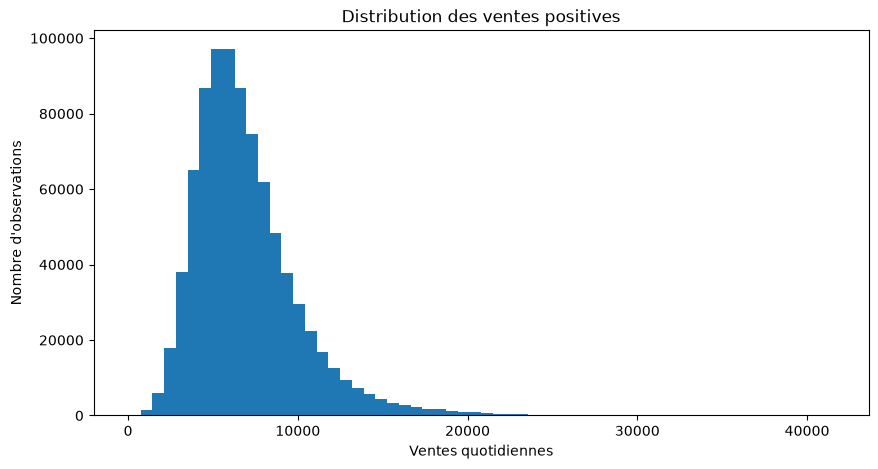

In [20]:
print("Nombre de ventes égales à zéro :", (train["Sales"] == 0).sum())
print("Ventes moyennes :", round(train["Sales"].mean(), 2))
print("Ventes médianes :", train["Sales"].median())
print("Ventes minimales :", train["Sales"].min())
print("Ventes maximales :", train["Sales"].max())

#Répartition des ventes
plt.figure(figsize=(10, 5))
plt.hist(train.loc[train["Sales"] > 0, "Sales"], bins=60)
plt.title("Distribution des ventes positives")
plt.xlabel("Ventes quotidiennes")
plt.ylabel("Nombre d'observations")
plt.show()

Promo
0    4406.050805
1    7991.152046
Name: Sales, dtype: float64


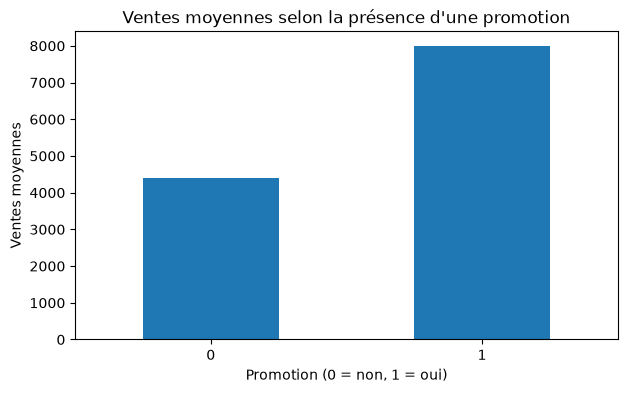

In [21]:

#Comparer les ventes avec et sans promotion
ventes_promo = train.groupby("Promo")["Sales"].mean()

print(ventes_promo)

ventes_promo.plot(kind="bar", figsize=(7, 4))
plt.title("Ventes moyennes selon la présence d'une promotion")
plt.xlabel("Promotion (0 = non, 1 = oui)")
plt.ylabel("Ventes moyennes")
plt.xticks(rotation=0)
plt.show()

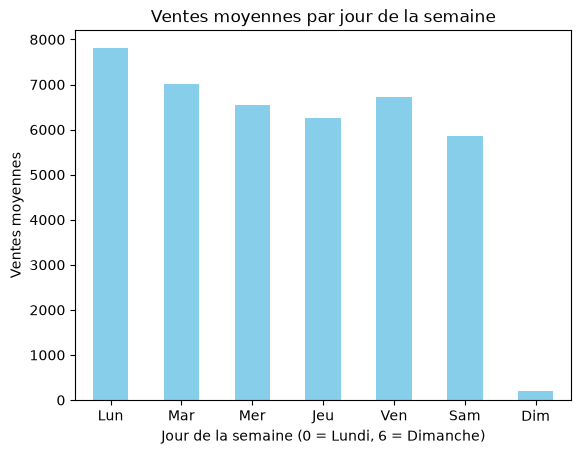

In [22]:
# nombre de vente moyenne selon le jour de la semaine
sales_by_day = train.groupby("DayOfWeek")["Sales"].mean()

# 4. Afficher un graphique en barres pour visualiser
sales_by_day.plot(kind="bar", color="skyblue")
plt.title("Ventes moyennes par jour de la semaine")
plt.xlabel("Jour de la semaine (0 = Lundi, 6 = Dimanche)")
plt.ylabel("Ventes moyennes")
plt.xticks(ticks=range(7), labels=["Lun", "Mar", "Mer", "Jeu", "Ven", "Sam", "Dim"], rotation=0)
plt.show()

In [23]:
# exemple d'une donnée avec le magasin associé
print("un",train_with_store.iloc[0])

un Store                                 1
DayOfWeek                             5
Date                         2015-07-31
Sales                              5263
Customers                           555
Open                                  1
Promo                                 1
StateHoliday                          0
SchoolHoliday                         1
StoreType                             c
Assortment                            a
CompetitionDistance              1270.0
CompetitionOpenSinceMonth           9.0
CompetitionOpenSinceYear         2008.0
Promo2                                0
Promo2SinceWeek                     NaN
Promo2SinceYear                     NaN
PromoInterval                       NaN
Name: 0, dtype: object


--- Ventes moyennes par type de magasin ---
StoreType
a     5738.179710
b    10058.837334
c     5723.629246
d     5641.819243
Name: Sales, dtype: float64


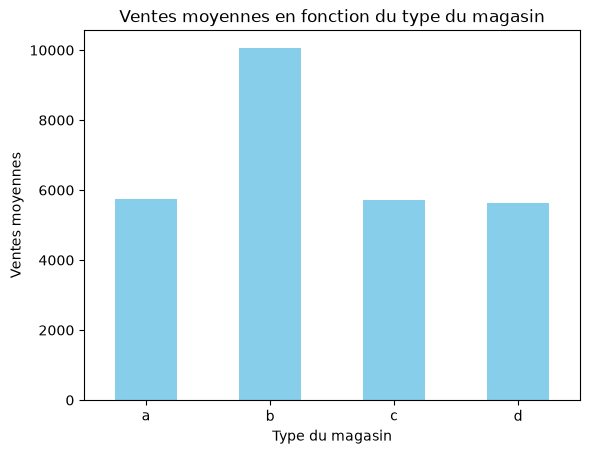

In [24]:
# 3. Obtenir les ventes moyennes selon le type de magasin (StoreType : a, b, c, d)
sales_by_store_type = train_with_store.groupby("StoreType")["Sales"].mean()

print("--- Ventes moyennes par type de magasin ---")
print(sales_by_store_type)

sales_by_store_type.plot(kind="bar", color="skyblue")
plt.title("Ventes moyennes en fonction du type du magasin")
plt.xlabel("Type du magasin")
plt.ylabel("Ventes moyennes")
plt.xticks(rotation=0)
plt.show()


--- Ventes moyennes par type de magasin ---
CompetitionDistance
20.0       4861.790870
30.0       4659.587470
40.0       6212.659448
50.0       8072.697452
60.0       7816.121373
              ...     
45740.0    6646.681529
46590.0    3773.877919
48330.0    4032.547771
58260.0    6071.001062
75860.0    7321.466030
Name: Sales, Length: 654, dtype: float64


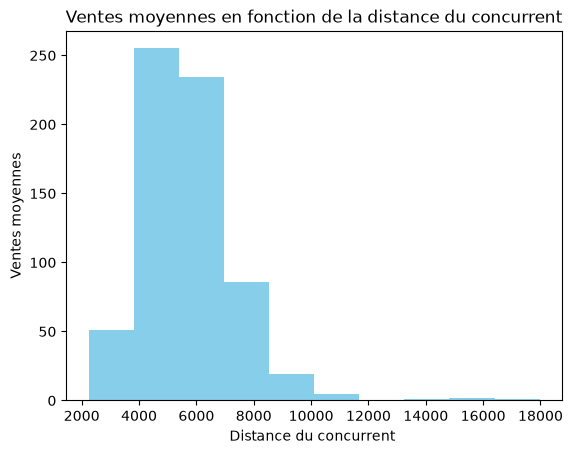

In [25]:
# 3. Obtenir les ventes moyennes selon le type de magasin (StoreType : a, b, c, d)
sales_by_store_type = train_with_store.groupby("CompetitionDistance")["Sales"].mean()

print("--- Ventes moyennes par type de magasin ---")
print(sales_by_store_type)

sales_by_store_type.plot(kind="hist", color="skyblue")
plt.title("Ventes moyennes en fonction de la distance du concurrent")
plt.xlabel("Distance du concurrent ")
plt.ylabel("Ventes moyennes")
plt.xticks(rotation=0)
plt.show()


# Traitement des données

In [26]:
# transformation des données en chiffre pour les rendre exploitable par l'IA
transformed_train_with_store = train_with_store.sort_values('Date').copy()

def transform_for_ia(df):
  # Transformation de PromoInterval en colonnes par mois (0 ou 1)
  tous_les_mois = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
  if 'PromoInterval' in df.columns:
      for mois in tous_les_mois:
          df[f'Promo_{mois}'] = df['PromoInterval'].astype(str).apply(lambda x: 1 if mois in x else 0)
      df.drop(columns=['PromoInterval'], inplace=True, errors='ignore')

  # Transformation de la Date en colonnes numériques (Année, Mois, Jour, Jour de la semaine)
  if 'Date' in df.columns:
      df['Date_time'] = pd.to_datetime(df['Date'])
      df['Year'] = df['Date_time'].dt.year
      df['Month'] = df['Date_time'].dt.month
      df['Day'] = df['Date_time'].dt.day
      df['DayOfWeek'] = df['Date_time'].dt.dayofweek
      df.drop(columns=['Date'], inplace=True)
  mapping_store = {"a": 1, "b": 2, "c": 3, "d": 4}
  df["StoreType"] = df["StoreType"].map(mapping_store)
  df["StateHoliday"] = df["StateHoliday"].map(mapping_store)
  df["Assortment"] = df["Assortment"].map(mapping_store)
  df["StateHoliday"] = pd.to_numeric(
      df["StateHoliday"],
      errors='raise'
  )
  df.fillna(0, inplace=True)
  return df

transformed_train_with_store =load_or_assign("transformed_train_with_store", lambda: transform_for_ia(transformed_train_with_store))
print(transformed_train_with_store.columns.tolist())
display(transformed_train_with_store.head(2))



['Store', 'DayOfWeek', 'Sales', 'Customers', 'Open', 'Promo', 'StateHoliday', 'SchoolHoliday', 'StoreType', 'Assortment', 'CompetitionDistance', 'CompetitionOpenSinceMonth', 'CompetitionOpenSinceYear', 'Promo2', 'Promo2SinceWeek', 'Promo2SinceYear', 'Promo_Jan', 'Promo_Feb', 'Promo_Mar', 'Promo_Apr', 'Promo_May', 'Promo_Jun', 'Promo_Jul', 'Promo_Aug', 'Promo_Sep', 'Promo_Oct', 'Promo_Nov', 'Promo_Dec', 'Date_time', 'Year', 'Month', 'Day']


,Store,DayOfWeek,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday,StoreType,Assortment,...,Promo_Jul,Promo_Aug,Promo_Sep,Promo_Oct,Promo_Nov,Promo_Dec,Date_time,Year,Month,Day
1017208,1115,1,0,0,0,0,1.0,1,4,3,...,0,0,1,0,0,1,2013-01-01,2013,1,1
1016473,379,1,0,0,0,0,1.0,1,4,1,...,0,0,0,0,0,0,2013-01-01,2013,1,1


In [27]:
transformed_test_with_store = load_or_assign("transformed_test_with_store",lambda: transform_for_ia(test_with_store))
print(transformed_test_with_store.columns.tolist())
display(transformed_test_with_store.head(2))
display(transformed_test_with_store[transformed_test_with_store["StoreType"]==1].head(2))

['Id', 'Store', 'DayOfWeek', 'Open', 'Promo', 'StateHoliday', 'SchoolHoliday', 'StoreType', 'Assortment', 'CompetitionDistance', 'CompetitionOpenSinceMonth', 'CompetitionOpenSinceYear', 'Promo2', 'Promo2SinceWeek', 'Promo2SinceYear', 'Promo_Jan', 'Promo_Feb', 'Promo_Mar', 'Promo_Apr', 'Promo_May', 'Promo_Jun', 'Promo_Jul', 'Promo_Aug', 'Promo_Sep', 'Promo_Oct', 'Promo_Nov', 'Promo_Dec', 'Date_time', 'Year', 'Month', 'Day']


,Id,Store,DayOfWeek,Open,Promo,StateHoliday,SchoolHoliday,StoreType,Assortment,CompetitionDistance,...,Promo_Jul,Promo_Aug,Promo_Sep,Promo_Oct,Promo_Nov,Promo_Dec,Date_time,Year,Month,Day
0,1,1,3,1.0,1,0.0,0,0.0,0.0,1270.0,...,0,0,0,0,0,0,2015-09-17,2015,9,17
1,2,3,3,1.0,1,0.0,0,0.0,0.0,14130.0,...,1,0,0,1,0,0,2015-09-17,2015,9,17


,Id,Store,DayOfWeek,Open,Promo,StateHoliday,SchoolHoliday,StoreType,Assortment,CompetitionDistance,...,Promo_Jul,Promo_Aug,Promo_Sep,Promo_Oct,Promo_Nov,Promo_Dec,Date_time,Year,Month,Day


In [28]:
# On garde la colonne d'origine "StoreType" intacte
# et on stocke le résultat dans une nouvelle variable indépendante

print(transformed_train_with_store.columns.tolist())
display(transformed_train_with_store.head(2))

['Store', 'DayOfWeek', 'Sales', 'Customers', 'Open', 'Promo', 'StateHoliday', 'SchoolHoliday', 'StoreType', 'Assortment', 'CompetitionDistance', 'CompetitionOpenSinceMonth', 'CompetitionOpenSinceYear', 'Promo2', 'Promo2SinceWeek', 'Promo2SinceYear', 'Promo_Jan', 'Promo_Feb', 'Promo_Mar', 'Promo_Apr', 'Promo_May', 'Promo_Jun', 'Promo_Jul', 'Promo_Aug', 'Promo_Sep', 'Promo_Oct', 'Promo_Nov', 'Promo_Dec', 'Date_time', 'Year', 'Month', 'Day']


,Store,DayOfWeek,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday,StoreType,Assortment,...,Promo_Jul,Promo_Aug,Promo_Sep,Promo_Oct,Promo_Nov,Promo_Dec,Date_time,Year,Month,Day
1017208,1115,1,0,0,0,0,1.0,1,4,3,...,0,0,1,0,0,1,2013-01-01,2013,1,1
1016473,379,1,0,0,0,0,1.0,1,4,1,...,0,0,0,0,0,0,2013-01-01,2013,1,1


In [29]:
display(transformed_train_with_store.head(3))

,Store,DayOfWeek,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday,StoreType,Assortment,...,Promo_Jul,Promo_Aug,Promo_Sep,Promo_Oct,Promo_Nov,Promo_Dec,Date_time,Year,Month,Day
1017208,1115,1,0,0,0,0,1.0,1,4,3,...,0,0,1,0,0,1,2013-01-01,2013,1,1
1016473,379,1,0,0,0,0,1.0,1,4,1,...,0,0,0,0,0,0,2013-01-01,2013,1,1
1016472,378,1,0,0,0,0,1.0,1,1,3,...,0,0,0,0,0,0,2013-01-01,2013,1,1


# Test avec LGBMRegressor

## Prédiction avec des données étiquetés

### Séparation des données d'entrainement

In [30]:
# --- 4. LE SPLIT TEMPOREL (On utilise 'Date_temp' pour couper) ---
# Par exemple, on prend tout ce qui est avant juin 2015 pour entraîner, et après pour valider
date_coupure = pd.to_datetime('2015-06-01')

train_set = transformed_train_with_store[transformed_train_with_store['Date_time'] < date_coupure]
val_set = transformed_train_with_store[transformed_train_with_store['Date_time'] >= date_coupure]

# 5. On sépare les Features (X) et la Cible (y -> 'Sales'), en dégageant la date et les colonnes inutiles
X_train = train_set.drop(columns=['Sales', 'Date', 'Date_time', 'Customers'], errors='ignore')
y_train = train_set['Sales']

X_val = val_set.drop(columns=['Sales', 'Date', 'Date_time', 'Customers'], errors='ignore')
y_val = val_set['Sales']

print("Train shape:", X_train.shape)
print("Validation shape:", X_val.shape)

Train shape: (949194, 29)
Validation shape: (68015, 29)


### Prédiction du modèle avec ses propres données d'entrainement

In [ ]:
# 1. Définis la liste de tes colonnes qui sont des catégories (adapte selon ton dataset)
colonnes_categorielles = ['Store', 'StoreType', 'Assortment', 'DayOfWeek', 'Month']

# 2. Entraînement du modèle LightGBM avec la gestion des catégories
def get_model():
  model = lgb.LGBMRegressor(
      n_estimators=1000,
      learning_rate=0.03,
      random_state=42
  )

  model.fit(
      X_train, y_train,
      eval_set=[(X_val, y_val)],
      categorical_feature=colonnes_categorielles, # <-- C'EST ICI QU'ON DIT À L'IA DE TRAITER ÇA COMME DES CLASSES
      callbacks=[lgb.early_stopping(stopping_rounds=50)]
  )
  return model
model = load_or_assign("lgbm_regressor_test_1", get_model)
# --- 3. COMMENT AFFICHER ET VOIR LES RÉSULTATS ---
# On prédit les ventes sur le jeu de validation (X_val)

predictions = model.predict(X_val)

ia_display.display_prediction_comparaison(predictions, y_val)

Comparaison Vraies ventes vs Prédictions de l'IA :


,Vraies_Ventes,Pred_Ventes
0,8074,8947.506179
1,12736,10258.537593
2,10536,10108.135120
3,13798,12789.668026
4,5581,6224.401690
5,13775,12734.531858
6,16517,14428.145818
7,12132,10682.865515
8,10981,9295.862821
9,7787,6224.835264



Erreur globale (RMSE) sur la validation : 866.16
Score RMSPE Rossmann : 13.53% (ou 0.1353 en valeur brute)


=== ANALYSE DES CORRÉLATIONS : VRAIES DONNÉES DE VALIDATION ===


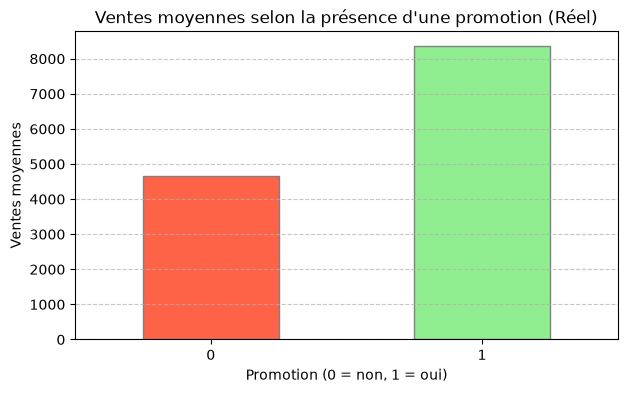

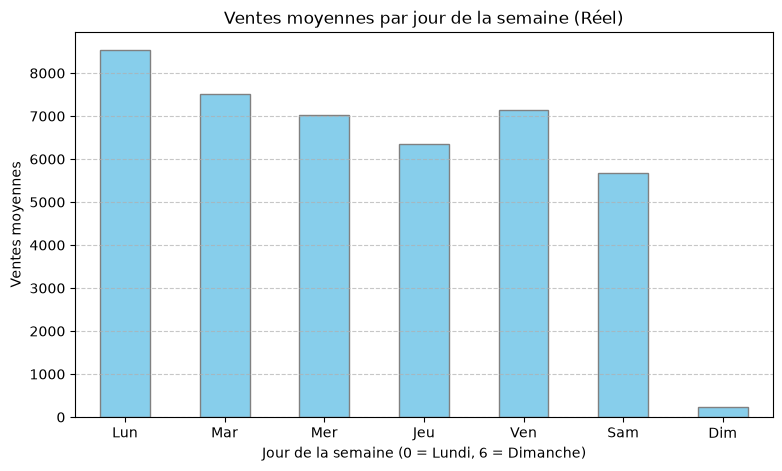

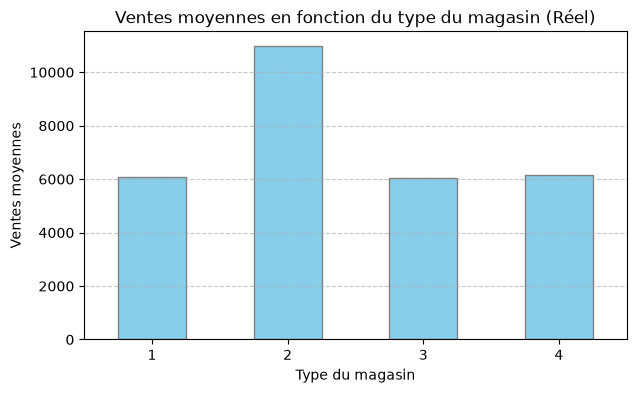

In [32]:
# Préparation d'un DataFrame de validation contenant à la fois les vraies ventes et les prédictions de l'IA
comparison_df = val_set.copy()
comparison_df['Predicted_Sales'] = predictions

print("=== ANALYSE DES CORRÉLATIONS : VRAIES DONNÉES DE VALIDATION ===")
gr.plot_sales_by_promo(comparison_df, sales_column='Sales', title_suffix='(Réel)')
gr.plot_sales_by_day(comparison_df, sales_column='Sales', title_suffix='(Réel)')
gr.plot_sales_by_store_type(comparison_df, sales_column='Sales', title_suffix='(Réel)')

=== ANALYSE DES CORRÉLATIONS : PRÉDICTIONS DE L'IA ===


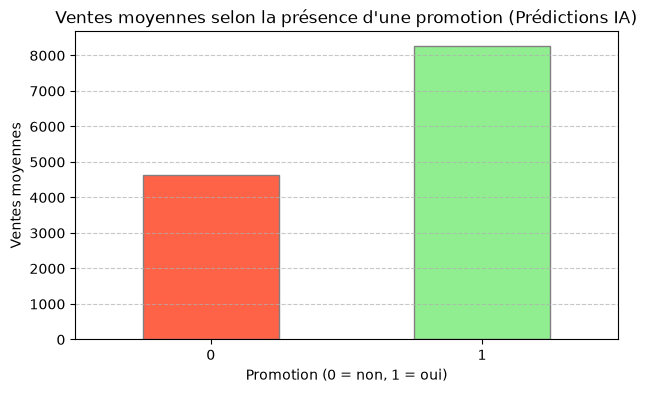

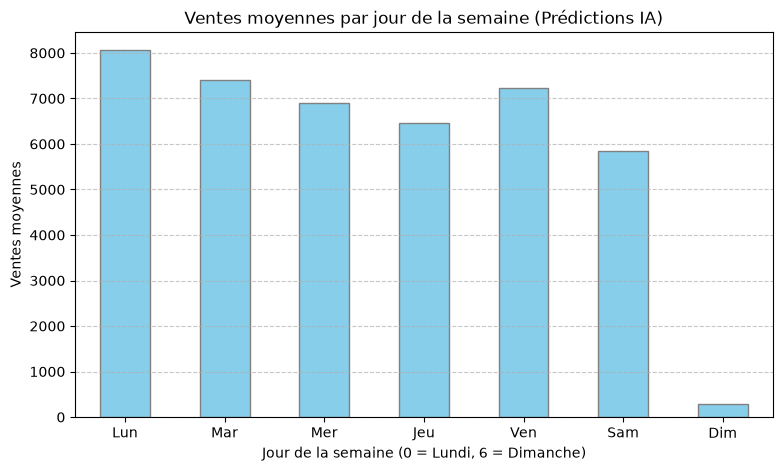

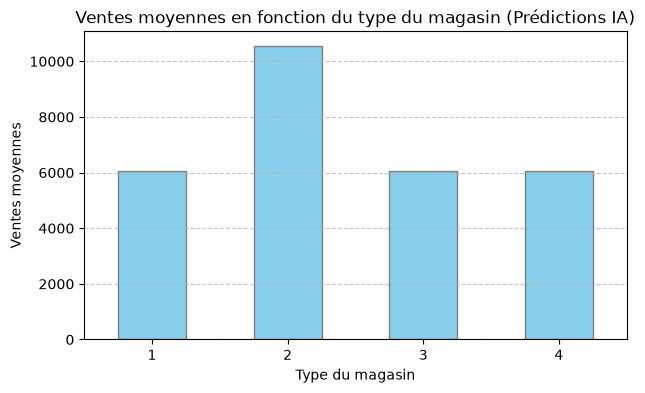

In [33]:
print("=== ANALYSE DES CORRÉLATIONS : PRÉDICTIONS DE L'IA ===")
gr.plot_sales_by_promo(comparison_df, sales_column='Predicted_Sales', title_suffix="(Prédictions IA)")
gr.plot_sales_by_day(comparison_df, sales_column='Predicted_Sales', title_suffix="(Prédictions IA)")
gr.plot_sales_by_store_type(comparison_df, sales_column='Predicted_Sales', title_suffix="(Prédictions IA)")

### Prédictions avec les données de test

In [34]:
test_val_set = transformed_test_with_store

X_val_test = test_val_set.drop(columns=['Date', 'Date_time',"Id", 'Customers'], errors='ignore')

# L'IA prédit uniquement avec les bonnes variables (sans l'Id)
predictions_test =model.predict(X_val_test)

# On fabrique le fichier final en remettant l'Id d'origine en face des prédictions
submission = pd.DataFrame({
    'Id': test['Id'],       # On prend l'Id d'origine qui était au chaud
    'Sales': predictions_test # On colle la prédiction de l'IA en face
})


submission.to_csv('submission_rossmann.csv', index=False)
display(submission)

,Id,Sales
0,1,4420.633890
1,2,7446.689486
2,3,8771.057523
3,4,6759.524942
4,5,7210.709920
...,...,...
41083,41084,4101.474039
41084,41085,7408.272912
41085,41086,6591.542065
41086,41087,22595.523894


Les résultat sur kaggle affiche un résultat de 0.14 environ pour ce modèle, nous allons augmenter les performances de l'ia pour qu'elle apprenne plus longtemp

## Deuxième itération de LGBMRegressor en améliorant les paramètres

### Prédictions avec les données d'entrainement

In [59]:
# 2. Entraînement du modèle LightGBM avec la gestion des catégories
def get_model():
  model = lgb.LGBMRegressor(
      n_estimators=3000,  # On augmente le plafond (l'early stopping coupera quand il faudra)
      learning_rate=0.015,  # On baisse un peu pour apprendre plus finement (au lieu de 0.03)
      num_leaves=63,  # Par défaut c'est 31. On monte à 63 pour capturer des relations plus complexes
      max_depth=-1,  # Laisse l'arbre grandir selon num_leaves
      subsample=0.8,  # Prend 80% des lignes par arbre (réduit le surapprentissage)
      colsample_bytree=0.8,  # Prend 80% des colonnes par arbre (ajoute de la diversité)
      random_state=42,
  )

  model.fit(
      X_train,
      y_train,
      eval_set=[(X_val, y_val)],
      categorical_feature=colonnes_categorielles,
      callbacks=[
          lgb.early_stopping(stopping_rounds=100)
      ],  # On pousse un peu à 100 tours pour être sûr
  )
  return model
model = load_or_assign("lgbm_regressor_test_2", get_model)
# --- 3. COMMENT AFFICHER ET VOIR LES RÉSULTATS ---
# On prédit les ventes sur le jeu de validation (X_val)

predictions = model.predict(X_val)

ia_display.display_prediction_comparaison(predictions, y_val)

[LightGBM] [Fatal] The number of features in data (33) is not the same as it was in training data (29).
You can set ``predict_disable_shape_check=true`` to discard this error, but please be aware what you are doing.


LightGBMError: The number of features in data (33) is not the same as it was in training data (29).
You can set ``predict_disable_shape_check=true`` to discard this error, but please be aware what you are doing.

### Prédiction avec les données de test

In [ ]:
test_val_set = transformed_test_with_store

X_val_test = test_val_set.drop(columns=['Date', 'Date_time',"Id", 'Customers'], errors='ignore')

# L'IA prédit uniquement avec les bonnes variables (sans l'Id)
predictions_test =model.predict(X_val_test)

# On fabrique le fichier final en remettant l'Id d'origine en face des prédictions
submission = pd.DataFrame({
    'Id': test['Id'],       # On prend l'Id d'origine qui était au chaud
    'Sales': predictions_test # On colle la prédiction de l'IA en face
})


submission.to_csv('submission_rossmann.csv', index=False)
display(submission)

,Id,Sales
0,1,4600.212571
1,2,7513.655306
2,3,8914.698626
3,4,6999.812833
4,5,7243.146326
...,...,...
41083,41084,4074.931413
41084,41085,7676.696115
41085,41086,6469.331819
41086,41087,22730.326859


In [ ]:
importance = pd.DataFrame({
    'Variable': X_train.columns,
    'Importance': model.feature_importances_,
}).sort_values(by='Importance', ascending=False)

print(importance.head(15))

                     Variable  Importance
0                       Store       39162
28                        Day       12248
27                      Month       11485
1                   DayOfWeek       10420
2                        Open        5206
3                       Promo        4078
26                       Year        4073
8         CompetitionDistance        3672
5               SchoolHoliday        1881
4                StateHoliday        1553
7                  Assortment        1375
6                   StoreType        1321
10   CompetitionOpenSinceYear        1153
9   CompetitionOpenSinceMonth        1036
12            Promo2SinceWeek         980


## Prédictions en ajoutant des lag features

### Ajout des variables de décalage (Lag Features)

Nous allons enrichir nos données d'entraînement et de test en ajoutant 4 nouvelles colonnes représentant l'état historique :
1. Ventes d'il y a 364 jours (`Sales_lag_364`)
2. Nombre de clients d'il y a 364 jours (`Customers_lag_364`)
3. Ventes d'il y a 49 jours (7 semaines) (`Sales_lag_49`)
4. Nombre de clients d'il y a 49 jours (7 semaines) (`Customers_lag_49`)

In [ ]:
import pandas as pd
import numpy as np

def add_lag_features(train_df, test_df):
    # 1. Création d'une base historique unifiée contenant Ventes et Clients pour chaque Magasin + Date
    # On s'assure d'avoir Date_time au bon format
    train_df['Date_time'] = pd.to_datetime(train_df['Date_time'])
    if 'Date_time' in test_df.columns:
        test_df['Date_time'] = pd.to_datetime(test_df['Date_time'])

    # Récupération de l'historique complet
    histo = train_df[['Store', 'Date_time', 'Sales', 'Customers']].copy()

    # Pour faire les jointures facilement
    histo = histo.set_index(['Store', 'Date_time'])

    # Fonction pour récupérer le décalage pour un dataframe cible
    def get_lags(target_df):
        target_df['Date_time'] = pd.to_datetime(target_df['Date_time'])

        # Calcul des dates cibles pour les lags
        date_364 = target_df['Date_time'] - pd.Timedelta(days=364)
        date_49 = target_df['Date_time'] - pd.Timedelta(days=49)

        # Clés de jointures
        key_364 = list(zip(target_df['Store'], date_364))
        key_49 = list(zip(target_df['Store'], date_49))

        # Reindexation rapide via l'index multi-niveau
        lag_364_data = histo.reindex(key_364).reset_index(drop=True)
        lag_49_data = histo.reindex(key_49).reset_index(drop=True)

        target_df['Sales_lag_364'] = lag_364_data['Sales'].values
        target_df['Customers_lag_364'] = lag_364_data['Customers'].values

        target_df['Sales_lag_49'] = lag_49_data['Sales'].values
        target_df['Customers_lag_49'] = lag_49_data['Customers'].values

        # Remplissage des valeurs manquantes créées par le décalage
        target_df.fillna({'Sales_lag_364': 0, 'Customers_lag_364': 0, 'Sales_lag_49': 0, 'Customers_lag_49': 0}, inplace=True)
        return target_df

    # Filtrage après le 2014-01-01
    train_filtered = train_df[train_df['Date_time'] >= '2014-01-01'].copy()
    test_filtered = test_df.copy() # Le jeu de test est entièrement en 2015

    print("Calcul des lags pour le jeu d'entraînement...")
    train_filtered = get_lags(train_filtered)

    print("Calcul des lags pour le jeu de test...")
    test_filtered = get_lags(test_filtered)

    return train_filtered, test_filtered

# Application de la transformation
trained_with_lags, test_with_lags = add_lag_features(transformed_train_with_store, transformed_test_with_store)

print("Dimensions après ajout des lags (Train) :", trained_with_lags.columns)
print("Dimensions après ajout des lags (Test) :", test_with_lags.columns)
display(trained_with_lags.head())


Calcul des lags pour le jeu d'entraînement...
Calcul des lags pour le jeu de test...
Dimensions après ajout des lags (Train) : Index(['Store', 'DayOfWeek', 'Sales', 'Customers', 'Open', 'Promo',
       'StateHoliday', 'SchoolHoliday', 'StoreType', 'Assortment',
       'CompetitionDistance', 'CompetitionOpenSinceMonth',
       'CompetitionOpenSinceYear', 'Promo2', 'Promo2SinceWeek',
       'Promo2SinceYear', 'Promo_Jan', 'Promo_Feb', 'Promo_Mar', 'Promo_Apr',
       'Promo_May', 'Promo_Jun', 'Promo_Jul', 'Promo_Aug', 'Promo_Sep',
       'Promo_Oct', 'Promo_Nov', 'Promo_Dec', 'Date_time', 'Year', 'Month',
       'Day', 'Sales_lag_364', 'Customers_lag_364', 'Sales_lag_49',
       'Customers_lag_49'],
      dtype='object')
Dimensions après ajout des lags (Test) : Index(['Id', 'Store', 'DayOfWeek', 'Open', 'Promo', 'StateHoliday',
       'SchoolHoliday', 'StoreType', 'Assortment', 'CompetitionDistance',
       'CompetitionOpenSinceMonth', 'CompetitionOpenSinceYear', 'Promo2',
       'Promo2

,Store,DayOfWeek,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday,StoreType,Assortment,...,Promo_Nov,Promo_Dec,Date_time,Year,Month,Day,Sales_lag_364,Customers_lag_364,Sales_lag_49,Customers_lag_49
609491,372,2,0,0,0,0,1.0,1,4,3,...,0,0,2014-01-01,2014,1,1,8014.0,769.0,5969.0,589.0
609487,368,2,0,0,0,0,1.0,1,4,3,...,1,0,2014-01-01,2014,1,1,7296.0,586.0,6469.0,576.0
609488,369,2,0,0,0,0,1.0,1,4,3,...,0,0,2014-01-01,2014,1,1,6063.0,541.0,5082.0,443.0
609489,370,2,0,0,0,0,1.0,1,4,1,...,0,0,2014-01-01,2014,1,1,5462.0,524.0,5431.0,490.0
609490,371,2,0,0,0,0,1.0,1,4,3,...,1,0,2014-01-01,2014,1,1,7374.0,606.0,5024.0,440.0


### Séparation des données

In [41]:
# --- 4. LE SPLIT TEMPOREL (On utilise 'Date_temp' pour couper) ---
# Par exemple, on prend tout ce qui est avant juin 2015 pour entraîner, et après pour valider
date_coupure = pd.to_datetime('2015-06-01')

train_set = trained_with_lags[trained_with_lags['Date_time'] < date_coupure]
val_set = trained_with_lags[trained_with_lags['Date_time'] >= date_coupure]

# 5. On sépare les Features (X) et la Cible (y -> 'Sales'), en dégageant la date et les colonnes inutiles
X_train = train_set.drop(columns=['Sales', 'Date', 'Date_time', 'Customers'], errors='ignore')
y_train = train_set['Sales']

X_val = val_set.drop(columns=['Sales', 'Date', 'Date_time', 'Customers'], errors='ignore')
y_val = val_set['Sales']

print("Train shape:", X_train.columns)
print("Validation shape:", X_val.shape)


Train shape: Index(['Store', 'DayOfWeek', 'Open', 'Promo', 'StateHoliday', 'SchoolHoliday',
       'StoreType', 'Assortment', 'CompetitionDistance',
       'CompetitionOpenSinceMonth', 'CompetitionOpenSinceYear', 'Promo2',
       'Promo2SinceWeek', 'Promo2SinceYear', 'Promo_Jan', 'Promo_Feb',
       'Promo_Mar', 'Promo_Apr', 'Promo_May', 'Promo_Jun', 'Promo_Jul',
       'Promo_Aug', 'Promo_Sep', 'Promo_Oct', 'Promo_Nov', 'Promo_Dec', 'Year',
       'Month', 'Day', 'Sales_lag_364', 'Customers_lag_364', 'Sales_lag_49',
       'Customers_lag_49'],
      dtype='object')
Validation shape: (68015, 33)


### Prédiction avec les données d'entrainemnts

In [ ]:
def get_model():
  model = lgb.LGBMRegressor(
      n_estimators=1000,
      learning_rate=0.03,
      random_state=42
  )

  model.fit(
      X_train, y_train,
      eval_set=[(X_val, y_val)],
      categorical_feature=colonnes_categorielles, # <-- C'EST ICI QU'ON DIT À L'IA DE TRAITER ÇA COMME DES CLASSES
      callbacks=[lgb.early_stopping(stopping_rounds=50)]
  )
  return model

model = load_or_assign("lgbm_regressor_test_3", get_model)

predictions = model.predict(X_val)

ia_display.display_prediction_comparaison(predictions, y_val)


Comparaison Vraies ventes vs Prédictions de l'IA :


,Vraies_Ventes,Pred_Ventes
0,8074,8983.368718
1,12736,12106.682423
2,10536,10570.942931
3,13798,15397.743075
4,5581,6245.294561
5,13775,13788.343871
6,16517,16337.937698
7,12132,11851.554129
8,10981,11092.803655
9,7787,6514.261286



Erreur globale (RMSE) sur la validation : 940.90
Score RMSPE Rossmann : 14.50% (ou 0.1450 en valeur brute)


### Prédictions avec les données de test

In [ ]:
X_val_test = test_with_lags.drop(columns=['Date', 'Date_time',"Id", 'Customers'], errors='ignore')

predictions = model.predict(X_val_test)

ia_display.create_and_display_submit_file(predictions, test)

,Id,Sales
0,1,4498.823851
1,2,8311.899321
2,3,9799.314007
3,4,7960.596399
4,5,7292.156592


## Prédiction en réduisant le nombre de jours de lag

In [ ]:
# --- Application de la transformation ---
trained_with_lags, test_with_lags = add_lag_features(transformed_train_with_store, transformed_test_with_store,['Sales', 'Customers'] ,[49,43])

print("Dimensions après ajout des lags (Train) :", trained_with_lags.columns)
print("Dimensions après ajout des lags (Test) :", test_with_lags.columns)
display(trained_with_lags.head())

Date minimale de l'historique : 2013-01-01
Lag maximum appliqué : 49 jours
Filtrage automatique du train à partir du : 2013-02-19
Calcul des lags pour le jeu d'entraînement...
Calcul des lags pour le jeu de test...
Dimensions après ajout des lags (Train) : Index(['Store', 'DayOfWeek', 'Sales', 'Customers', 'Open', 'Promo',
       'StateHoliday', 'SchoolHoliday', 'StoreType', 'Assortment',
       'CompetitionDistance', 'CompetitionOpenSinceMonth',
       'CompetitionOpenSinceYear', 'Promo2', 'Promo2SinceWeek',
       'Promo2SinceYear', 'Promo_Jan', 'Promo_Feb', 'Promo_Mar', 'Promo_Apr',
       'Promo_May', 'Promo_Jun', 'Promo_Jul', 'Promo_Aug', 'Promo_Sep',
       'Promo_Oct', 'Promo_Nov', 'Promo_Dec', 'Date_time', 'Year', 'Month',
       'Day', 'Sales_lag_49', 'Sales_lag_43', 'Customers_lag_49',
       'Customers_lag_43'],
      dtype='object')
Dimensions après ajout des lags (Test) : Index(['Id', 'Store', 'DayOfWeek', 'Open', 'Promo', 'StateHoliday',
       'SchoolHoliday', 'StoreType

,Store,DayOfWeek,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday,StoreType,Assortment,...,Promo_Nov,Promo_Dec,Date_time,Year,Month,Day,Sales_lag_49,Sales_lag_43,Customers_lag_49,Customers_lag_43
961831,372,1,9104,734,1,1,0.0,0,4,3,...,0,0,2013-02-19,2013,2,19,0.0,13478.0,0.0,1037.0
961827,368,1,9547,668,1,1,0.0,0,4,3,...,1,0,2013-02-19,2013,2,19,0.0,16406.0,0.0,1042.0
961828,369,1,6332,491,1,1,0.0,0,4,3,...,0,0,2013-02-19,2013,2,19,0.0,8969.0,0.0,689.0
961829,370,1,6675,508,1,1,0.0,0,4,1,...,0,0,2013-02-19,2013,2,19,0.0,11205.0,0.0,813.0
961830,371,1,8001,561,1,1,0.0,0,4,3,...,1,0,2013-02-19,2013,2,19,0.0,11134.0,0.0,810.0


### Prédiction avec les données d'entrainement 

In [60]:
X_train, y_train, X_val, y_val = format_data.create_train_value(trained_with_lags)

In [61]:
model = load_or_assign("lgbm_regressor_test_4", get_model)
predictions = model.predict(X_val)
ia_display.display_prediction_comparaison(predictions, y_val)

/home/mthvn/code/Deep learning/.venv/lib/python3.15/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


[LightGBM] [Warning] Categorical features with more bins than the configured maximum bin number found.
[LightGBM] [Warning] For categorical features, max_bin and max_bin_by_feature may be ignored with a large number of categories.
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.079490 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 2547
[LightGBM] [Info] Number of data points in the train set: 894560, number of used features: 33
[LightGBM] [Info] Start training from score 5771.810193
Training until validation scores don't improve for 100 rounds
Did not meet early stopping. Best iteration is:
[2996]	valid_0's l2: 750121
Comparaison Vraies ventes vs Prédictions de l'IA :


,Vraies_Ventes,Pred_Ventes
0,8074,9262.214093
1,12736,11030.435454
2,10536,10721.761609
3,13798,14176.442992
4,5581,6084.925268
5,13775,13591.835823
6,16517,14780.484271
7,12132,10974.936451
8,10981,9905.356666
9,7787,5987.282956



Erreur globale (RMSE) sur la validation : 866.10
Score RMSPE Rossmann : 13.05% (ou 0.1305 en valeur brute)
